# WildSpeech M8.6 — M0++ Item-Response Intelligence & Competitive Screening

**Research objective:** improve the frozen M8.5 E04 candidate (student pooled OOF R²≈0.2126) using B1 full-feature fusion, B2 monotone additive theta model, item-response and Rasch features, instrument partial pooling, and clip-duration nuisance controls.

**Interpretation:** M8.4 reference is formally approved, M8.5 E04 has an exploratory HOLD_REFERENCE decision. The code has separate engineering submission and scientific claims. Reported public R²≈0.5 is NOT a local model score and must not be compared directly.

**Data safety:** Google Drive first, private student-level outputs, original frozen folds and OOF untouched, no external inference APIs, no audio reads, no test-data fitting. No online leaderboard submission.

The first run is SCREEN; change MODE to FULL for all 50 student plus 50 school-disjoint folds. FULL is computationally substantial and checkpointed.

## 0 · Mount private Google Drive

Expected existing folders: `MyDrive/WildSpeech/`, `WildSpeech_M84/phase0/`, `WildSpeech_M85/m0plus/`.

In [1]:
import sys,os,json,subprocess,importlib,time
from pathlib import Path
from IPython.display import display,Markdown,Image
import pandas as pd
import numpy as np
try:
    IN_COLAB=importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive",force_remount=False)
    DRIVE=Path("/content/drive/MyDrive")
else:
    DRIVE=Path(os.environ.get("WILDSPEECH_DRIVE_ROOT",str(Path.home()/"MyDrive")))
assert DRIVE.is_dir(),f"Private Drive not mounted at {DRIVE}"
print("Drive:",DRIVE)

Mounted at /content/drive
Drive: /content/drive/MyDrive


## 1 · Install versioned GitHub package

The commit SHA is stored with every experiment. No ZIP upload or untracked direct notebook code is used.

In [2]:
GITHUB="https://github.com/mybenkhadda/WildSpeech.git"
CHECKOUT=Path("/content/WildSpeech_git") if IN_COLAB else Path.cwd()/"WildSpeech_git"
if not (CHECKOUT/".git").is_dir():
    if CHECKOUT.exists():raise RuntimeError(f"Directory exists but is not a Git checkout: {CHECKOUT}")
    subprocess.run(["git","clone","--depth","1","--branch","main",GITHUB,str(CHECKOUT)],check=True)
else:
    subprocess.run(["git","-C",str(CHECKOUT),"pull","--ff-only","origin","main"],check=True)
PKG=CHECKOUT/"WildSpeech_M8"
subprocess.run([sys.executable,"-m","pip","install","-q","-e",str(PKG)],check=True)
src=str(PKG/"src")
if src not in sys.path:sys.path.insert(0,src)
from wildspeech_m86.experiments import execute,EXPERIMENTS,plan
from wildspeech_m86.contracts import FULL_FOLD_HASH
from wildspeech_m84.data import load_official,locate_data_root,digest_bytes
GIT_SHA=subprocess.check_output(["git","-C",str(CHECKOUT),"rev-parse","HEAD"],text=True).strip()
print("M8.6 source SHA:",GIT_SHA)

M8.6 source SHA: 92c19051756a1080d13f4d81c87cba257c293de6


## 2 · Mode selection

SCREEN is exploratory and executes only the first five student + five school folds with a single lightweight CatBoost seed. FULL uses **all eleven preregistered models**, the full immutable 100-fold protocol, five CatBoost seeds and fixed hyperparameters.

The original Phase 0, M8.5 reports, and OOF predictions are READ ONLY. The outputs of SCREEN and FULL live in separate versioned subdirectories.

In [3]:
MODE="FULL"                 # change to "FULL" only after initial diagnostics
EXPERIMENT_IDS=list(EXPERIMENTS)
DATA_ROOT_OVERRIDE=""
PHASE0_ROOT=DRIVE/"WildSpeech_M84"/"phase0"
M85_ROOT=DRIVE/"WildSpeech_M85"/"m0plus"
OUTPUT_ROOT=DRIVE/"WildSpeech_M86"/"m0pp"
EXPECTED_FOLD_HASH=FULL_FOLD_HASH
EXPORT_CANDIDATE=True        # only FULL, and only if engineering gate passes
EXPORT_E04_DIAGNOSTIC=False  # explicit opt-in; old HOLD_REFERENCE is preserved
assert MODE in ("SCREEN","FULL")
assert PHASE0_ROOT.joinpath("folds","folds.parquet").exists()
assert M85_ROOT.joinpath("reports","M85_RESULTS.json").exists()
print("Mode:",MODE)
print("Output:",OUTPUT_ROOT/MODE.lower())

Mode: FULL
Output: /content/drive/MyDrive/WildSpeech_M86/m0pp/full


## 3 · Freeze and verify E00 and E04 anchors

The experiment runner validates official source CSV SHA-256 values, metadata/label student order, the 100 stored folds, M8.4 reference OOF, E04 OOF checksum and completed M8.5 ledger before creating candidate runs.

In [4]:
DATA_ROOT=locate_data_root(DRIVE,DATA_ROOT_OVERRIDE)
DATA=load_official(DATA_ROOT)
M85_HISTORY=json.loads((M85_ROOT/"reports"/"M85_RESULTS.json").read_text())
print("M8.5 mode:",M85_HISTORY["mode"],"decision:",M85_HISTORY["decision"])
print("Reference frozen mean-fold R²:",M85_HISTORY["reference"]["mean_fold_r2"])
e04=next(r for r in M85_HISTORY["model_metrics"] if r["model"]=="E04")
display(pd.DataFrame([{"model":"E04",**e04}]).T)
print("Locked fold hash:",M85_HISTORY["fold_hash"])
assert M85_HISTORY["fold_hash"]==FULL_FOLD_HASH
assert M85_HISTORY["mode"]=="FULL" and M85_HISTORY["completed_all_E01_E09"]
print("Train/test:",len(DATA.train_students),len(DATA.test_students))
print("Train/test clip rows:",len(DATA.train_clips),len(DATA.test_clips))

M8.5 mode: FULL decision: HOLD_REFERENCE
Reference frozen mean-fold R²: 0.1932274944147675


,0
model,E04
corrected_t,1.371267
gate,HOLD
gate_reason,Positive improvement but below one or more pro...
instrument_delta_r2,"{'ktea3': 0.012807302954008226, 'wj4': 0.01484..."
mean_fold_delta_r2,0.014558
mean_fold_r2,0.207786
mean_school_pooled_r2,0.156023
mean_student_pooled_delta_r2,0.013518
mean_student_pooled_r2,0.212631


Locked fold hash: 6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1
Train/test: 541 361
Train/test clip rows: 14704 9814


## 4 · Explicit experimental preregistration

**B1** Ridge/CatBoost fusion on full E04 features; **B2** constrained monotone theta GAM; **B3** S0+S2+S3; **I1–I5** item-response matrix, Rasch, item complexity, difficulty profiles and bundle; **D2/D3** partial pooling; **T1** item×score-normalized clip duration.

'First error', 'last three errors' and 'furthest reached' are **disabled** because the official schema does not provide verified item chronology.

In [5]:
PLAN=pd.DataFrame(plan())
display(PLAN[["comparison_id","baseline","challenger","primary_science_test"]])
print("Comparisons:",len(PLAN))
print("Primary predefined science hypotheses: B1, B2, I5")
print("Engineering rule: positive pooled Δ, ≥65% wins, school Δ≥−.005, instrument Δ≥−.01")
print("Science rule: mean fold Δ≥+.01, corrected t≥2, ≥60% wins + same robustness vetoes")

,comparison_id,baseline,challenger,primary_science_test
0,B1_VS_E04,E04_M85,B1,True
1,B2_VS_E04,E04_M85,B2,True
2,B3_VS_E04,E04_M85,B3,False
3,I1_VS_E04,E04_M85,I1,False
4,I2_VS_E04,E04_M85,I2,False
5,I3_VS_E04,E04_M85,I3,False
6,I4_VS_E04,E04_M85,I4,False
7,I5_VS_E04,E04_M85,I5,True
8,D2_VS_E04,E04_M85,D2,False
9,D3_VS_E04,E04_M85,D3,False


Comparisons: 11
Primary predefined science hypotheses: B1, B2, I5
Engineering rule: positive pooled Δ, ≥65% wins, school Δ≥−.005, instrument Δ≥−.01
Science rule: mean fold Δ≥+.01, corrected t≥2, ≥60% wins + same robustness vetoes


## 5 · Review data protocol and item feature validity

In [6]:
from wildspeech_m86.contracts import prompt_key
trainclips=DATA.train_clips
print("Observed tasks:",sorted(trainclips.task.unique()))
print("Has raw expected prompt text:","expected_text" in trainclips)
print("Item score available on hidden test:",
      ("item_score" in DATA.test_clips) and DATA.test_clips.item_score.notna().any())
print("No verified item order:",not any(x in trainclips for x in
     ("item_order","item_sequence","timestamp","start_time")))
print("Features do NOT include future outcome, score_status, school, child ID or filename.")

Observed tasks: ['blending', 'deletion', 'sentence_repetition']
Has raw expected prompt text: True
Item score available on hidden test: True
No verified item order: True
Features do NOT include future outcome, score_status, school, child ID or filename.


## 6 · Execute M8.6 screening/full experiment engine

The heavy work is performed by the library and saved to Drive one fold at a time. It builds inner training-only item/difficulty/spline representations separately from the outer fold and never accesses held-out outcomes during feature fitting.

In FULL, every challenger is paired against the exact saved E04 OOF; both engineering eligibility and scientific evidence are reported. No public submission occurs.

In [7]:
start=time.perf_counter()
RESULT=execute(
    drive_root=DRIVE,
    data_root_override=DATA_ROOT_OVERRIDE,
    phase0_root_override=str(PHASE0_ROOT),
    phase1_root_override=str(M85_ROOT),
    output_root_override=str(OUTPUT_ROOT),
    mode=MODE,
    models=tuple(EXPERIMENT_IDS),
    export_candidate=EXPORT_CANDIDATE,
    export_diagnostic_e04=EXPORT_E04_DIAGNOSTIC,
    expected_fold_hash=EXPECTED_FOLD_HASH,
)
print("Completed/reused",MODE,"in",round(time.perf_counter()-start,1),"seconds")
print("Decision:",RESULT["decision"],"winner:",RESULT["winner"])
print("Reference SHA:",RESULT["reference_oof_sha256"])
print("E04 SHA:",RESULT["e04_oof_sha256"])

[M86] mode=FULL decision=ENGINEERING_CANDIDATE winner=I5
[M86] report=/content/drive/MyDrive/WildSpeech_M86/m0pp/full/reports/M86_DECISION.md
Completed/reused FULL in 161.1 seconds
Decision: ENGINEERING_CANDIDATE winner: I5
Reference SHA: a7ecccb0b647f39ff5363d15117484612edfd081cd9d5496f2d55a4ab59bd05d
E04 SHA: 87eec3952fad769ae5952d247588e297e3e176e0269ef39d3a9644cfd0e5ed32


## 7 · Screening reference and comparative performance

Mean pooled OOF student R² is a different estimand from mean-of-50-fold R². Both are reported, as are MAE, RMSE and school generalization.

In [8]:
ROOT=OUTPUT_ROOT/MODE.lower()
METRICS=pd.DataFrame(RESULT["model_metrics"])
columns=[c for c in ["model","mean_fold_r2","student_pooled_r2",
    "school_pooled_r2","student_mae","student_rmse",
    "paired_fold_delta_r2","paired_student_pooled_delta_r2",
    "paired_school_delta_r2","win_fraction","corrected_t",
    "submission_eligible","science_gate"] if c in METRICS]
display(METRICS[columns].round(6))
if MODE=="SCREEN":
    print("SCREEN is engineering exploration, not confirmatory model evaluation.")
else:
    print("FULL completed:",RESULT["n_student_folds"],"student and",
          RESULT["n_school_folds"],"school-heldout folds")

,model,mean_fold_r2,student_pooled_r2,school_pooled_r2,student_mae,student_rmse,paired_fold_delta_r2,paired_student_pooled_delta_r2,paired_school_delta_r2,win_fraction,corrected_t,submission_eligible,science_gate
0,E04,0.207786,0.212631,0.156023,7.261894,9.872334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E00,0.193227,0.199113,0.147363,7.370509,9.956738,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B1,0.216058,0.221372,0.154949,7.246867,9.817363,0.008272,0.008741,-0.001074,0.82,0.627800,True,False
3,B2,0.204299,0.209201,0.146100,7.283917,9.893792,-0.003487,-0.003430,-0.009923,0.26,-0.483568,False,False
4,B3,0.203812,0.208652,0.157246,7.278826,9.897287,-0.003974,-0.003979,0.001222,0.32,-0.789771,False,False
5,I1,0.230622,0.234419,0.149354,7.131374,9.734720,0.022836,0.021787,-0.006670,0.76,1.272145,False,False
6,I2,0.211229,0.216047,0.153570,7.234740,9.850938,0.003444,0.003416,-0.002454,0.68,0.692923,True,False
7,I3,0.217073,0.220934,0.170194,7.172550,9.820187,0.009287,0.008303,0.014170,0.72,1.157823,True,False
8,I4,0.219130,0.223811,0.170575,7.199795,9.802036,0.011345,0.011179,0.014552,0.90,1.678608,True,False
9,I5,0.233248,0.237018,0.157147,7.112271,9.718189,0.025462,0.024386,0.001123,0.76,1.355333,True,False


FULL completed: 50 student and 50 school-heldout folds


## 8 · Figures: item support, instrument task administration, model gains

01_item_support.png


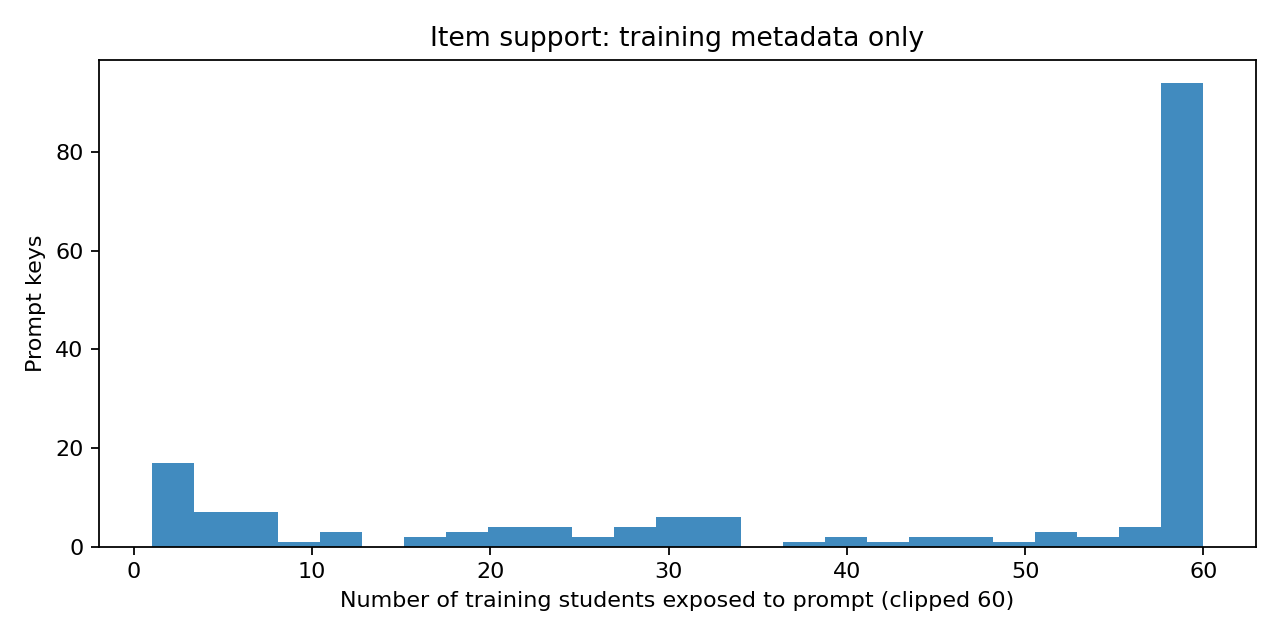

02_task_admin_by_instrument.png


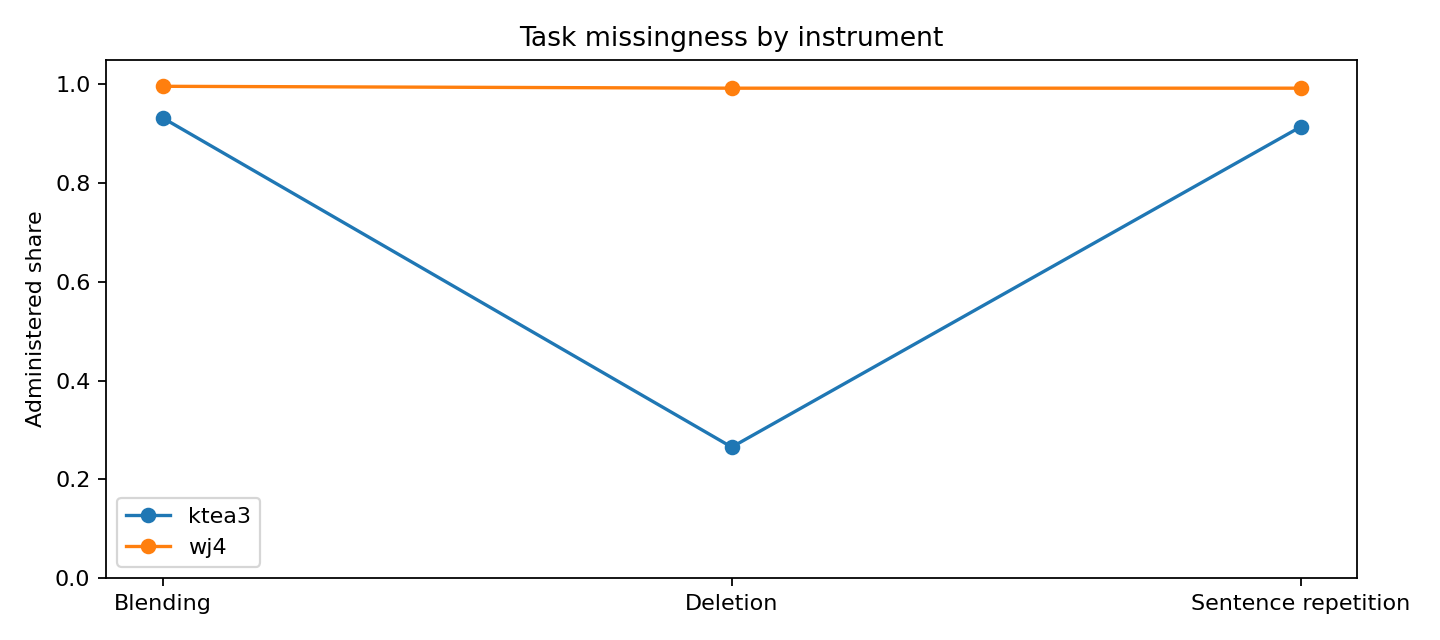

03_model_performance.png


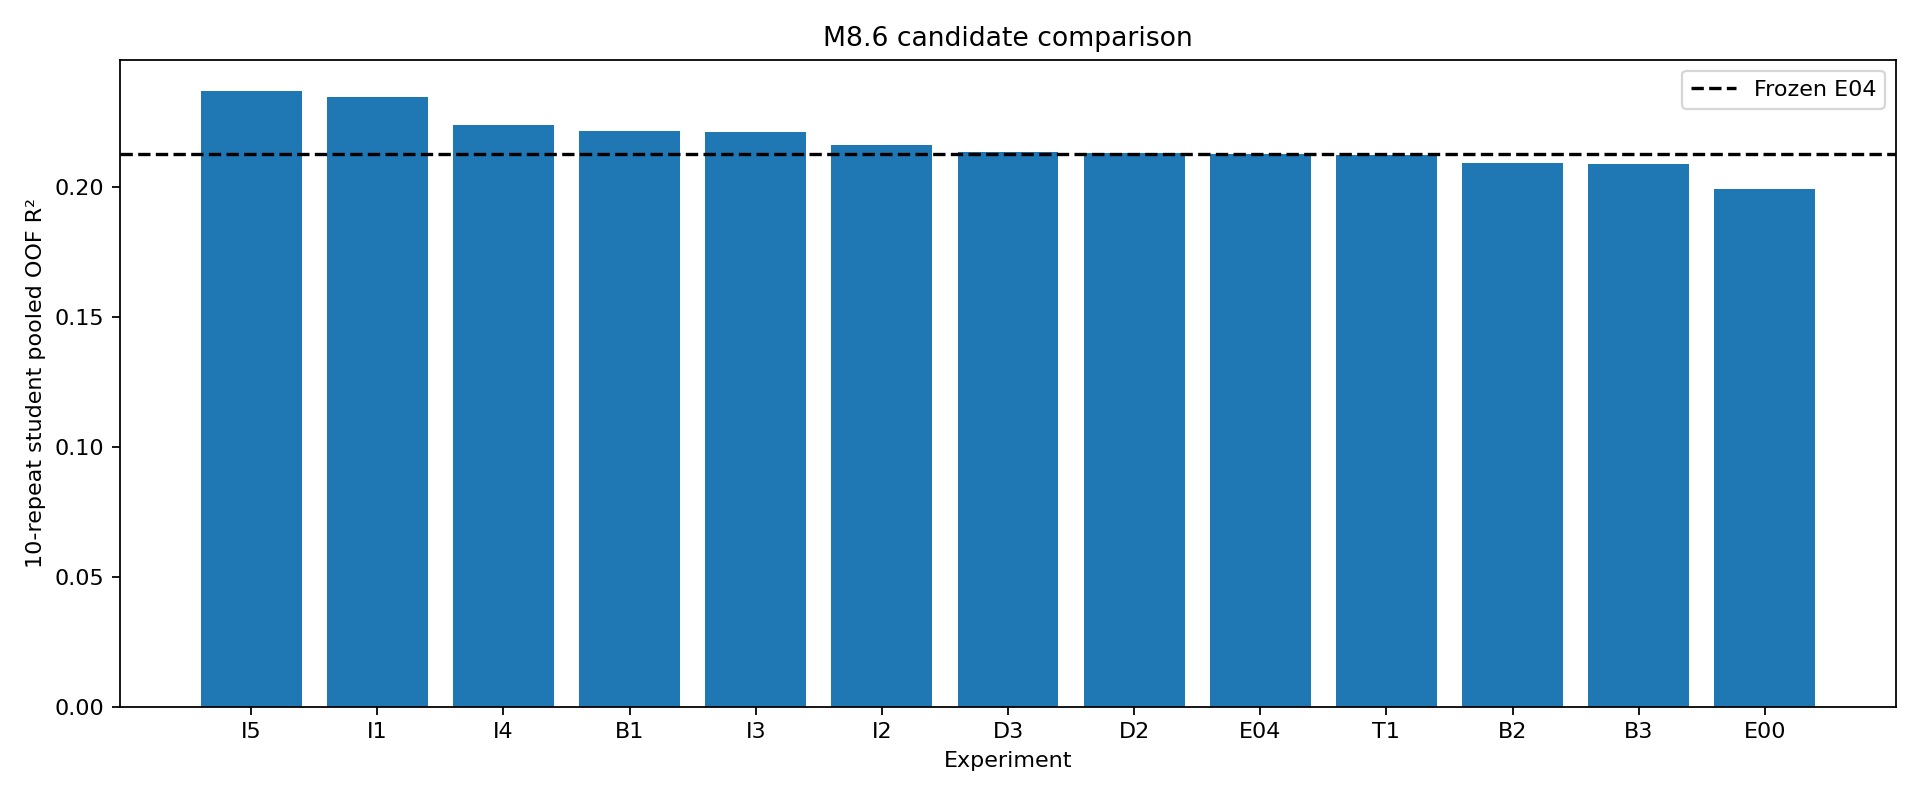

04_paired_deltas.png


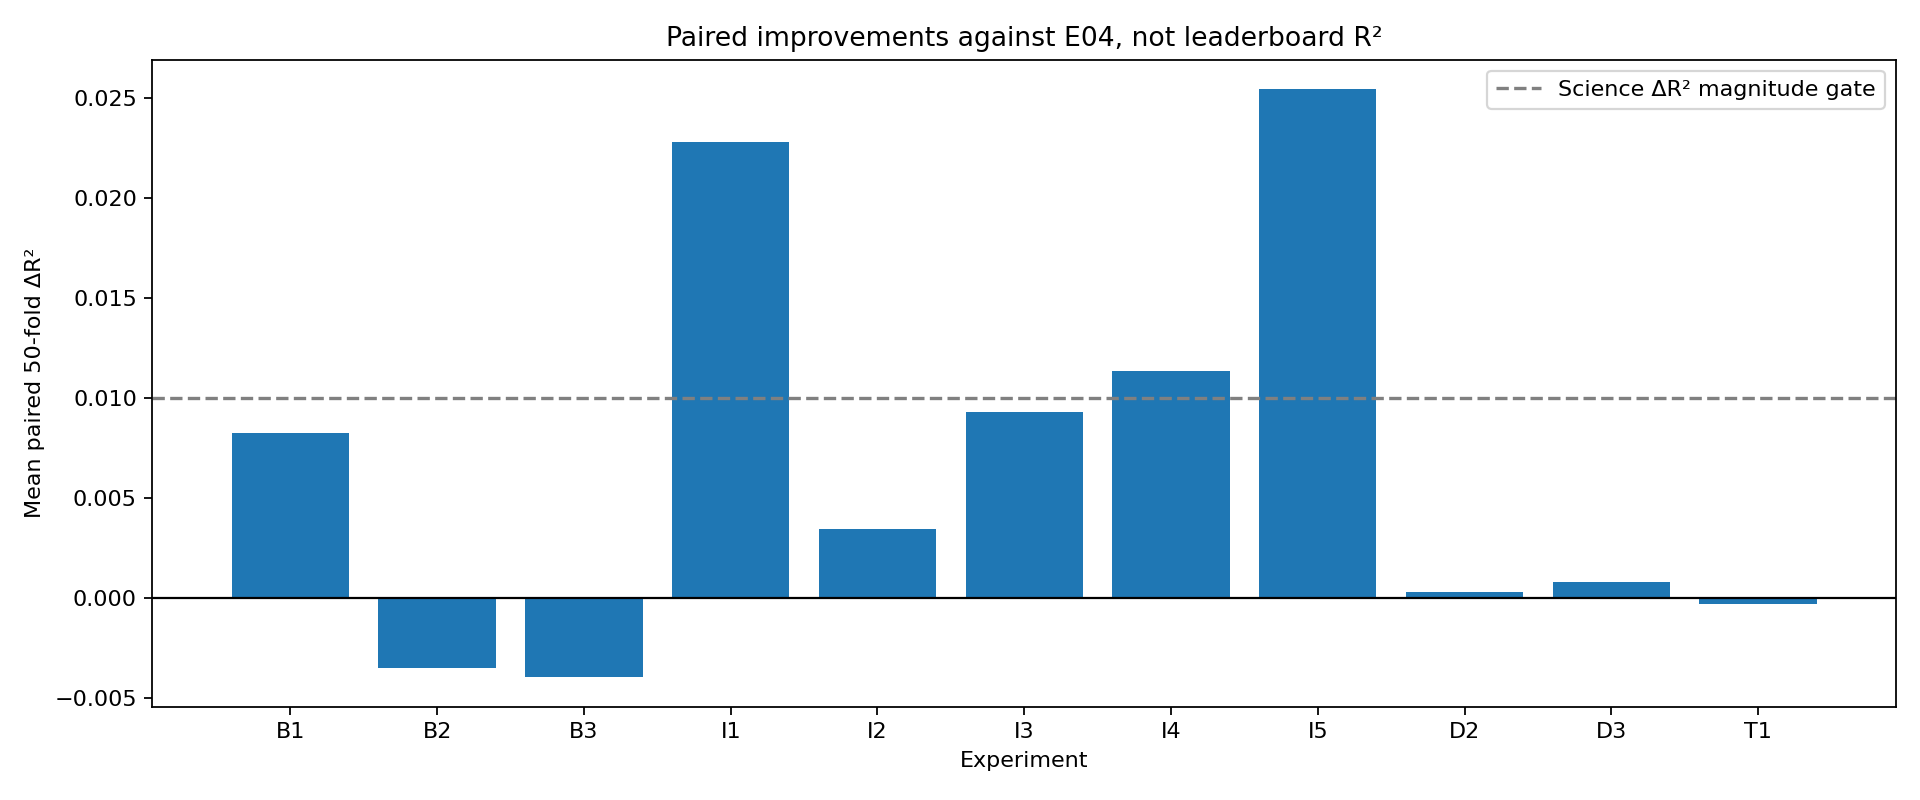

05_school_transfer.png


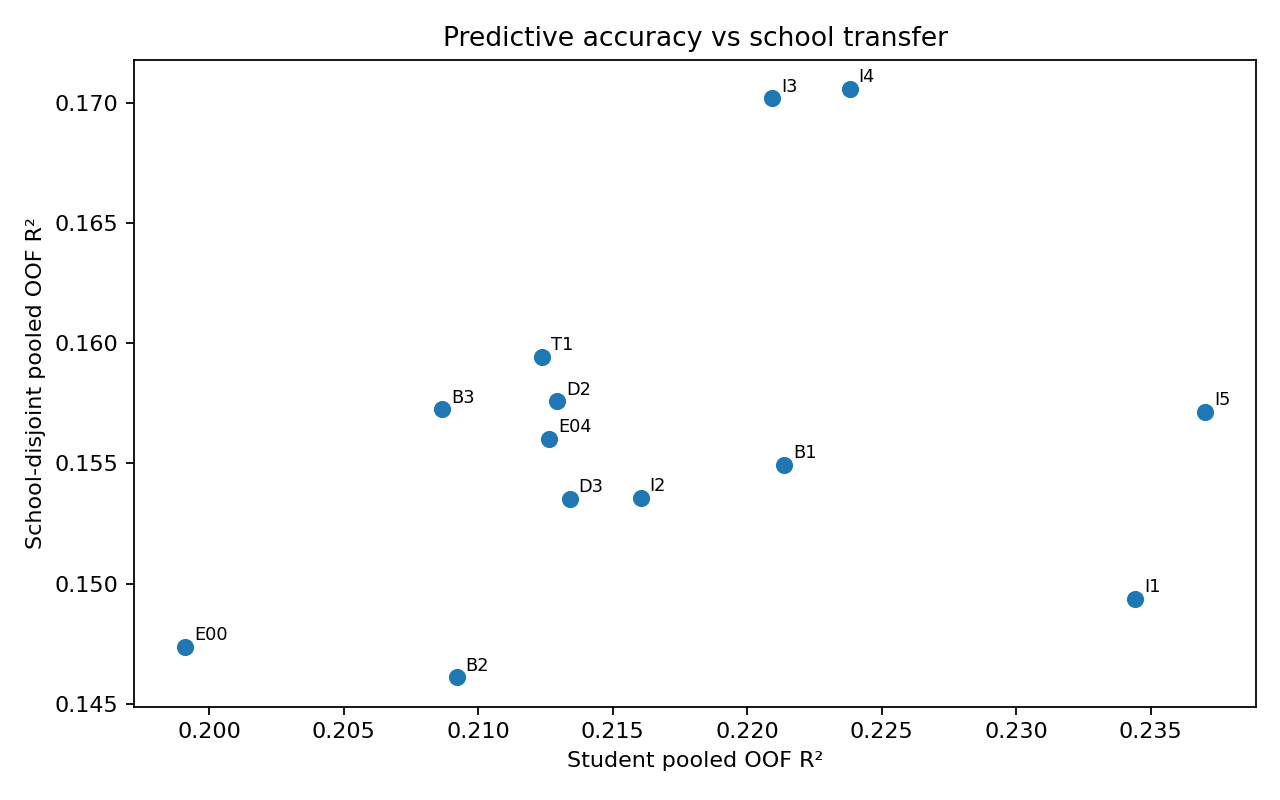

In [9]:
FIGURES=ROOT/"figures"
for filename in ["01_item_support.png","02_task_admin_by_instrument.png",
                 "03_model_performance.png","04_paired_deltas.png",
                 "05_school_transfer.png"]:
    p=FIGURES/filename
    if p.is_file():
        print(filename)
        display(Image(filename=str(p)))

## 9 · Examine private item identity and complexity atlas

These tables are for internal research; do not commit child-level, school-level or scored-item records to public GitHub.

In [10]:
TAB=ROOT/"tables"
for filename in ("diagnostic_summary.json","task_missingness_by_instrument.csv",
                 "instrument_transfer_suppressed.csv"):
    p=TAB/filename
    if p.suffix==".json":
        print(filename,json.loads(p.read_text()))
    else:
        print(filename);display(pd.read_csv(p))
print("Prompt identifiers are task+normalized expected_text, NOT temporal order.")

diagnostic_summary.json {'n_instruments': 2, 'n_item_keys': 178, 'n_rare_le_2': 13, 'n_schools': 17, 'n_students': 541, 'school_max': 153, 'school_min': 1}
task_missingness_by_instrument.csv


,instrument,administered,theta_present,task
0,ktea3,0.931900,0.921147,blending
1,wj4,0.996183,0.958015,blending
2,ktea3,0.265233,0.265233,deletion
3,wj4,0.992366,0.977099,deletion
4,ktea3,0.913978,0.913978,sentence_repetition
5,wj4,0.992366,0.988550,sentence_repetition


instrument_transfer_suppressed.csv


,scheme,instrument,n,mae,avg_bias
0,school,ktea3,277,8.485882,0.389797
1,school,wj4,259,6.669572,-0.434968
2,student,ktea3,277,8.144815,0.335143
3,student,wj4,259,6.625224,-0.423834


Prompt identifiers are task+normalized expected_text, NOT temporal order.


## 10 · Investigate nonlinear theta models and item-response gains

For B2, nonnegative hinge coefficients guarantee monotonicity in the input theta, conditional on other observed covariates. The free S3 splines and theta×instrument terms are omitted from B2.

I2 is a strongly regularized 1PL Rasch model. Item parameters are trained only on other students for each training representation; real test item parameters come from all 541 training students.

In [11]:
selected=METRICS[METRICS.model.isin(["E04","B1","B2","B3","I1","I2","I3","I4","I5"])]
display(selected[columns].round(6))
print("Complexity metrics are orthographic proxies, not verified phoneme counts.")
print("Rasch theta and its standard error are model-derived and may differ in scale from official theta.")

,model,mean_fold_r2,student_pooled_r2,school_pooled_r2,student_mae,student_rmse,paired_fold_delta_r2,paired_student_pooled_delta_r2,paired_school_delta_r2,win_fraction,corrected_t,submission_eligible,science_gate
0,E04,0.207786,0.212631,0.156023,7.261894,9.872334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B1,0.216058,0.221372,0.154949,7.246867,9.817363,0.008272,0.008741,-0.001074,0.82,0.627800,True,False
3,B2,0.204299,0.209201,0.146100,7.283917,9.893792,-0.003487,-0.003430,-0.009923,0.26,-0.483568,False,False
4,B3,0.203812,0.208652,0.157246,7.278826,9.897287,-0.003974,-0.003979,0.001222,0.32,-0.789771,False,False
5,I1,0.230622,0.234419,0.149354,7.131374,9.734720,0.022836,0.021787,-0.006670,0.76,1.272145,False,False
6,I2,0.211229,0.216047,0.153570,7.234740,9.850938,0.003444,0.003416,-0.002454,0.68,0.692923,True,False
7,I3,0.217073,0.220934,0.170194,7.172550,9.820187,0.009287,0.008303,0.014170,0.72,1.157823,True,False
8,I4,0.219130,0.223811,0.170575,7.199795,9.802036,0.011345,0.011179,0.014552,0.90,1.678608,True,False
9,I5,0.233248,0.237018,0.157147,7.112271,9.718189,0.025462,0.024386,0.001123,0.76,1.355333,True,False


Complexity metrics are orthographic proxies, not verified phoneme counts.
Rasch theta and its standard error are model-derived and may differ in scale from official theta.


## 11 · Instrument partial pooling and clip duration nuisance controls

D2 uses a common regression with penalized instrument-specific deviations. D3 uses the observed deletion-available indicator with shrinkage toward the global regression.

T1 normalizes **clip duration** by prompt and item score using training-fold statistics only. It does not claim response latency or child-specific voice activity.

In [12]:
subset=METRICS[METRICS.model.isin(["E04","D2","D3","T1"])]
display(subset[columns].round(6))
print("Any T1 gain must be treated as a possible protocol/recording contribution.")

,model,mean_fold_r2,student_pooled_r2,school_pooled_r2,student_mae,student_rmse,paired_fold_delta_r2,paired_student_pooled_delta_r2,paired_school_delta_r2,win_fraction,corrected_t,submission_eligible,science_gate
0,E04,0.207786,0.212631,0.156023,7.261894,9.872334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,D2,0.208090,0.212941,0.157584,7.257767,9.870392,0.000304,0.000310,0.001560,0.68,0.606081,True,False
11,D3,0.208574,0.213399,0.153515,7.258149,9.867538,0.000788,0.000768,-0.002508,0.78,0.433700,True,False
12,T1,0.207466,0.212371,0.159430,7.271026,9.873958,-0.000319,-0.000260,0.003407,0.54,-0.082986,False,False


Any T1 gain must be treated as a possible protocol/recording contribution.


## 12 · FULL paired evaluation and separate decision rules

In [13]:
if MODE=="FULL":
    COMP=pd.read_csv(TAB/"paired_comparisons.csv")
    display(COMP.round(6))
    print("Engineering candidate:",RESULT["winner"])
    print("Predeclared primary science checks:",RESULT["science_primary"])
else:
    print("No pairwise t-statistic or model promotion is valid from SCREEN.")

,comparison,candidate,baseline,mean_fold_delta_r2,student_pooled_delta_r2,school_pooled_delta_r2,corrected_t,fold_win_fraction,instrument_deltas,submission_eligible,science_gate
0,B1_VS_E04,B1,E04,0.008272,0.008741,-0.001074,0.627800,0.82,"{'ktea3': 0.02029971743228102, 'wj4': -0.00929...",True,False
1,B2_VS_E04,B2,E04,-0.003487,-0.003430,-0.009923,-0.483568,0.26,"{'ktea3': 0.0004903315902704209, 'wj4': -0.009...",False,False
2,B3_VS_E04,B3,E04,-0.003974,-0.003979,0.001222,-0.789771,0.32,"{'ktea3': -0.005378571574937196, 'wj4': -0.001...",False,False
3,I1_VS_E04,I1,E04,0.022836,0.021787,-0.006670,1.272145,0.76,"{'ktea3': 0.04243538171976134, 'wj4': -0.01033...",False,False
4,I2_VS_E04,I2,E04,0.003444,0.003416,-0.002454,0.692923,0.68,"{'ktea3': 0.0032744795458545806, 'wj4': 0.0036...",True,False
5,I3_VS_E04,I3,E04,0.009287,0.008303,0.014170,1.157823,0.72,"{'ktea3': 0.009139665040857791, 'wj4': 0.00711...",True,False
6,I4_VS_E04,I4,E04,0.011345,0.011179,0.014552,1.678608,0.90,"{'ktea3': 0.012107507977610833, 'wj4': 0.00989...",True,False
7,I5_VS_E04,I5,E04,0.025462,0.024386,0.001123,1.355333,0.76,"{'ktea3': 0.044670714314066176, 'wj4': -0.0071...",True,False
8,D2_VS_E04,D2,E04,0.000304,0.000310,0.001560,0.606081,0.68,"{'ktea3': 6.544422801544326e-05, 'wj4': 0.0007...",True,False
9,D3_VS_E04,D3,E04,0.000788,0.000768,-0.002508,0.433700,0.78,"{'ktea3': 0.0010589077512433765, 'wj4': 0.0003...",True,False


Engineering candidate: I5
Predeclared primary science checks: {'B1': False, 'B2': False, 'I5': False}


## 13 · Submission files and official score recording

Generated candidate CSVs are NOT uploaded automatically. The E04 diagnostic CSV is a separate opt-in output and is **not** a change to the historical HOLD_REFERENCE decision.

Once uploaded through the competition website, manually record receipt, timestamp, public R², model checksum and Git SHA. Do not tune repeatedly to the public subset.

In [14]:
if RESULT.get("candidate_submission"):
    cand=RESULT["candidate_submission"]
    print("M8.6 candidate file:",cand["csv"])
    print("SHA256:",cand["sha256"])
    assert cand["all_test_singleton_checked"] and cand["test_permutation_checked"]
else:
    print("No candidate exported. SCREEN or engineering veto kept the output private.")
if RESULT.get("diagnostic_e04"):
    print("E04 diagnostic:",RESULT["diagnostic_e04"]["submission"]["file"]
          if "file" in RESULT["diagnostic_e04"]["submission"] else
          RESULT["diagnostic_e04"]["submission"])

M8.6 candidate file: /content/drive/MyDrive/WildSpeech_M86/m0pp/full/submission/m0pp_submission.csv
SHA256: 58ac98547859ffa97557668ee7c65d25ebbcbab321523f8b23c1cbbe78a1924a


## 14 · Private report and ledger

The report differentiates screening hypotheses, engineering selection, scientific evidence, and remaining limitations. Inspect null findings as well as positive ones.

In [15]:
REPORT=ROOT/"reports"/"M86_DECISION.md"
assert REPORT.is_file()
display(Markdown(REPORT.read_text(encoding="utf-8")))
ledger=pd.read_parquet(ROOT/"ledger"/"experiments.parquet")
display(ledger[[c for c in ["model_id","status","git_sha","fold_hash",
                            "mean_fold_r2","mean_pooled_oof_r2"] if c in ledger]].tail(20))

# WildSpeech M8.6 — M0++ Decision and Research Results

**Mode:** FULL
**Engineering decision:** ENGINEERING_CANDIDATE
**Winner:** I5
**No online leaderboard submission has been made by this code.**

## Frozen evaluation anchors

- M8.4 fold SHA-256: 6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1
- M8.4 reference OOF SHA-256: a7ecccb0b647f39ff5363d15117484612edfd081cd9d5496f2d55a4ab59bd05d
- M8.5 E04 OOF SHA-256: 87eec3952fad769ae5952d247588e297e3e176e0269ef39d3a9644cfd0e5ed32
- Student-level repeated folds: 50
- Held-out-school folds: 50

The frozen reference and E04 OOF files were **read**, never rewritten.
Outer validation outcomes are NEVER supplied to feature builders or inner tuning.

## All models

| model   |   mean_fold_r2 |   student_pooled_r2 |   school_pooled_r2 |   student_mae |   student_rmse |   n_folds |   paired_fold_delta_r2 |   paired_student_pooled_delta_r2 |   paired_school_delta_r2 |   win_fraction |   corrected_t |   submission_eligible |   science_gate |
|:--------|---------------:|--------------------:|-------------------:|--------------:|---------------:|----------:|-----------------------:|---------------------------------:|-------------------------:|---------------:|--------------:|----------------------:|---------------:|
| E04     |        0.20779 |             0.21263 |            0.15602 |       7.26189 |        9.87233 |       100 |              nan       |                        nan       |                nan       |      nan       |     nan       |             nan       |      nan       |
| E00     |        0.19323 |             0.19911 |            0.14736 |       7.37051 |        9.95674 |       100 |              nan       |                        nan       |                nan       |      nan       |     nan       |             nan       |      nan       |
| B1      |        0.21606 |             0.22137 |            0.15495 |       7.24687 |        9.81736 |       100 |                0.00827 |                          0.00874 |                 -0.00107 |        0.82000 |       0.62780 |               1.00000 |        0.00000 |
| B2      |        0.20430 |             0.20920 |            0.14610 |       7.28392 |        9.89379 |       100 |               -0.00349 |                         -0.00343 |                 -0.00992 |        0.26000 |      -0.48357 |               0.00000 |        0.00000 |
| B3      |        0.20381 |             0.20865 |            0.15725 |       7.27883 |        9.89729 |       100 |               -0.00397 |                         -0.00398 |                  0.00122 |        0.32000 |      -0.78977 |               0.00000 |        0.00000 |
| I1      |        0.23062 |             0.23442 |            0.14935 |       7.13137 |        9.73472 |       100 |                0.02284 |                          0.02179 |                 -0.00667 |        0.76000 |       1.27215 |               0.00000 |        0.00000 |
| I2      |        0.21123 |             0.21605 |            0.15357 |       7.23474 |        9.85094 |       100 |                0.00344 |                          0.00342 |                 -0.00245 |        0.68000 |       0.69292 |               1.00000 |        0.00000 |
| I3      |        0.21707 |             0.22093 |            0.17019 |       7.17255 |        9.82019 |       100 |                0.00929 |                          0.00830 |                  0.01417 |        0.72000 |       1.15782 |               1.00000 |        0.00000 |
| I4      |        0.21913 |             0.22381 |            0.17058 |       7.19979 |        9.80204 |       100 |                0.01134 |                          0.01118 |                  0.01455 |        0.90000 |       1.67861 |               1.00000 |        0.00000 |
| I5      |        0.23325 |             0.23702 |            0.15715 |       7.11227 |        9.71819 |       100 |                0.02546 |                          0.02439 |                  0.00112 |        0.76000 |       1.35533 |               1.00000 |        0.00000 |
| D2      |        0.20809 |             0.21294 |            0.15758 |       7.25777 |        9.87039 |       100 |                0.00030 |                          0.00031 |                  0.00156 |        0.68000 |       0.60608 |               1.00000 |        0.00000 |
| D3      |        0.20857 |             0.21340 |            0.15352 |       7.25815 |        9.86754 |       100 |                0.00079 |                          0.00077 |                 -0.00251 |        0.78000 |       0.43370 |               1.00000 |        0.00000 |
| T1      |        0.20747 |             0.21237 |            0.15943 |       7.27103 |        9.87396 |       100 |               -0.00032 |                         -0.00026 |                  0.00341 |        0.54000 |      -0.08299 |               0.00000 |        0.00000 |

## Scientific evidence interpretation

Submission gate: pooled student ΔR² >0; at least 65% student fold wins; school ΔR² >= -0.005; every instrument ΔR² >= -0.010.
Scientific-effect gate: mean-fold ΔR² >= +0.010, corrected t >=2, fold wins >=60%, and same school/instrument vetoes.
The corrected t is an approximate repeated-CV statistic and is not adjusted for all exploratory model comparisons. Model selection on the same folds makes formal effect claims conditional rather than independent confirmation.

## Paired comparisons

| comparison   | candidate   | baseline   |   mean_fold_delta_r2 |   student_pooled_delta_r2 |   school_pooled_delta_r2 |   corrected_t |   fold_win_fraction | instrument_deltas                                               | submission_eligible   | science_gate   |
|:-------------|:------------|:-----------|---------------------:|--------------------------:|-------------------------:|--------------:|--------------------:|:----------------------------------------------------------------|:----------------------|:---------------|
| B1_VS_E04    | B1          | E04        |              0.00827 |                   0.00874 |                 -0.00107 |       0.62780 |             0.82000 | {'ktea3': 0.02029971743228102, 'wj4': -0.009298025556521983}    | True                  | False          |
| B2_VS_E04    | B2          | E04        |             -0.00349 |                  -0.00343 |                 -0.00992 |      -0.48357 |             0.26000 | {'ktea3': 0.0004903315902704209, 'wj4': -0.009649351571384324}  | False                 | False          |
| B3_VS_E04    | B3          | E04        |             -0.00397 |                  -0.00398 |                  0.00122 |      -0.78977 |             0.32000 | {'ktea3': -0.005378571574937196, 'wj4': -0.0018405228845585597} | False                 | False          |
| I1_VS_E04    | I1          | E04        |              0.02284 |                   0.02179 |                 -0.00667 |       1.27215 |             0.76000 | {'ktea3': 0.04243538171976134, 'wj4': -0.010339868272966624}    | False                 | False          |
| I2_VS_E04    | I2          | E04        |              0.00344 |                   0.00342 |                 -0.00245 |       0.69292 |             0.68000 | {'ktea3': 0.0032744795458545806, 'wj4': 0.003691862035965765}   | True                  | False          |
| I3_VS_E04    | I3          | E04        |              0.00929 |                   0.00830 |                  0.01417 |       1.15782 |             0.72000 | {'ktea3': 0.009139665040857791, 'wj4': 0.007118188435120942}    | True                  | False          |
| I4_VS_E04    | I4          | E04        |              0.01134 |                   0.01118 |                  0.01455 |       1.67861 |             0.90000 | {'ktea3': 0.012107507977610833, 'wj4': 0.009896290335182046}    | True                  | False          |
| I5_VS_E04    | I5          | E04        |              0.02546 |                   0.02439 |                  0.00112 |       1.35533 |             0.76000 | {'ktea3': 0.044670714314066176, 'wj4': -0.007128052451834499}   | True                  | False          |
| D2_VS_E04    | D2          | E04        |              0.00030 |                   0.00031 |                  0.00156 |       0.60608 |             0.68000 | {'ktea3': 6.544422801544326e-05, 'wj4': 0.0007005965592932872}  | True                  | False          |
| D3_VS_E04    | D3          | E04        |              0.00079 |                   0.00077 |                 -0.00251 |       0.43370 |             0.78000 | {'ktea3': 0.0010589077512433765, 'wj4': 0.00032224200551154156} | True                  | False          |
| T1_VS_E04    | T1          | E04        |             -0.00032 |                  -0.00026 |                  0.00341 |      -0.08299 |             0.54000 | {'ktea3': 4.390160650131758e-05, 'wj4': -0.0007417710763498065} | False                 | False          |

## Compliance and limitation notes

- No student/school identity, train-only score_status, raw audio, or future reading outcome is a predictor.
- Item difficulty, Rasch item parameters, time-normalization references and spline knots are trained inside folds.
- Training Rasch representations are student-crossfitted; item summary priors are student-LOO.
- 'Duration' here means total clip duration, **not** prompt-end-to-child-response latency.
- Phoneme count and true lexical frequency are NOT asserted; item complexity here uses transparent orthographic proxies.
- Sentence-repeat partial credit and child speech localization belong to M8.7.
- Existing M8.5 HOLD_REFERENCE is not retroactively changed by an M8.6 diagnostic submission.

## Decision

I5 passes preregistered engineering robustness and paired win gates. It was selected on the same repeated folds, so the corrected statistic is not an independent confirmatory result.

## Outputs

- Private Parquet OOF and fold checkpoints under runs/
- Figures 01–05 and private tables under figures/ and tables/
- Candidate submission (only when eligible) under submission/
- No raw competition rows or model state are committed to GitHub.



,model_id,status,git_sha,fold_hash,mean_fold_r2,mean_pooled_oof_r2
0,M86_B1,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.216058,0.221372
1,M86_B2,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.204299,0.209201
2,M86_B3,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.203812,0.208652
3,M86_I1,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.230622,0.234419
4,M86_I2,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.211229,0.216047
5,M86_I3,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.217073,0.220934
6,M86_I4,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.219130,0.223811
7,M86_I5,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.233248,0.237018
8,M86_D2,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.208090,0.212941
9,M86_D3,COMPLETE,92c19051756a1080d13f4d81c87cba257c293de6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.208574,0.213399


## 15 · Phase 2 / M8.7 handoff

The research priority after M0++ is to establish genuine child speech evidence, not another broad STFT feature sweep.

Model licenses, per-checkpoint hashes, local-only inference, child response localization QA, sentence-repetition partial credit, blending/deletion near-misses, unscored-clip recovery, and recording-condition controls are the M8.7 entry criteria.

Current M8.6 **does not** perform pretrained phonetic inference or use audio, and cannot be cited as new child-speech evidence.